**Q-Learning Using FrozenLake**

Install and Import Libraries

In [6]:
!pip install -q gymnasium numpy matplotlib

import gymnasium as gym
import numpy as np
import matplotlib.pyplot as plt

Q-learning Training Function

In [7]:
def train_q_learning(
    epsilon_decay,
    seed=42,
    episodes=20000,
    learning_rate=0.8,
    discount_factor=0.95,
    epsilon_start=1.0,
    epsilon_min=0.01,
    max_steps=100
):
    # Create a fresh FrozenLake environment for this experiment
    env = gym.make("FrozenLake-v1", is_slippery=True)

    # Seed the environment, action space, and NumPy random generator
    env.reset(seed=seed)
    env.action_space.seed(seed)
    rng = np.random.default_rng(seed)

    state_size = env.observation_space.n
    action_size = env.action_space.n
    q_table = np.zeros((state_size, action_size))

    epsilon = epsilon_start
    episode_rewards = []
    episode_successes = []

    for episode in range(episodes):
        state, info = env.reset()
        total_reward = 0
        terminated = False
        truncated = False

        for step in range(max_steps):
            # Epsilon-greedy action selection
            if rng.random() < epsilon:
                action = int(rng.integers(action_size))
            else:
                action = int(np.argmax(q_table[state]))

            next_state, reward, terminated, truncated, info = env.step(action)

            # Q-learning update; do not bootstrap after an episode ends
            old_value = q_table[state, action]
            next_max = 0 if (terminated or truncated) else np.max(q_table[next_state])

            q_table[state, action] = old_value + learning_rate * (
                reward + discount_factor * next_max - old_value
            )

            state = next_state
            total_reward += reward

            if terminated or truncated:
                break

        episode_rewards.append(total_reward)
        episode_successes.append(1 if total_reward > 0 else 0)

        # AI-suggested improvement: tune epsilon decay
        epsilon = max(epsilon_min, epsilon * epsilon_decay)

    env.close()
    return q_table, np.array(episode_rewards), np.array(episode_successes)


def moving_average(values, window=500):
    return np.convolve(values, np.ones(window) / window, mode="valid")

Baseline Training

In [8]:
EPISODES = 20000
SEED = 42

baseline_q, baseline_rewards, baseline_successes = train_q_learning(
    epsilon_decay=0.9999,
    seed=SEED,
    episodes=EPISODES
)

print("Baseline training complete.")
print("Baseline success rate over final 2,000 episodes:",
      f"{baseline_successes[-2000:].mean():.2%}")

Baseline training complete.
Baseline success rate over final 2,000 episodes: 11.30%


AI-suggested Improvement: Tune Epsilon Decay

In [9]:
improved_q, improved_rewards, improved_successes = train_q_learning(
    epsilon_decay=0.9995,
    seed=SEED,
    episodes=EPISODES
)

print("Improved training complete.")
print("Improved success rate over final 2,000 episodes:",
      f"{improved_successes[-2000:].mean():.2%}")

Improved training complete.
Improved success rate over final 2,000 episodes: 43.40%


Before-and-after Comparison: Rewards over Time

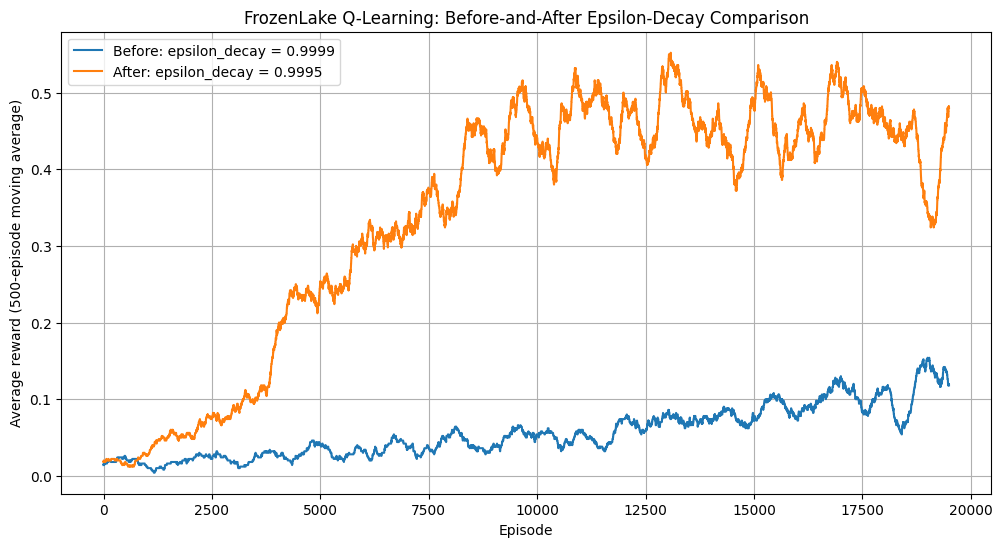

Baseline final-window success rate: 11.30%
Improved final-window success rate: 43.40%


In [14]:
window = 500

baseline_avg = moving_average(baseline_rewards, window)
improved_avg = moving_average(improved_rewards, window)

plt.figure(figsize=(12, 6))
plt.plot(baseline_avg, label="Before: epsilon_decay = 0.9999")
plt.plot(improved_avg, label="After: epsilon_decay = 0.9995")
plt.title("FrozenLake Q-Learning: Before-and-After Epsilon-Decay Comparison")
plt.xlabel("Episode")
plt.ylabel(f"Average reward ({window}-episode moving average)")
plt.legend()
plt.grid(True)
plt.show()

print("Baseline final-window success rate:",
      f"{baseline_successes[-2000:].mean():.2%}")
print("Improved final-window success rate:",
      f"{improved_successes[-2000:].mean():.2%}")

Evaluate the Trained Agents

In [12]:
def evaluate_agent(q_table, episodes=100, seed=123):
    eval_env = gym.make("FrozenLake-v1", is_slippery=True)
    eval_env.reset(seed=seed)

    successful_episodes = 0
    evaluation_rewards = []

    for episode in range(episodes):
        state, info = eval_env.reset()
        terminated = False
        truncated = False
        total_reward = 0

        while not (terminated or truncated):
            action = int(np.argmax(q_table[state]))
            state, reward, terminated, truncated, info = eval_env.step(action)
            total_reward += reward

        evaluation_rewards.append(total_reward)
        if total_reward > 0:
            successful_episodes += 1

    eval_env.close()
    return successful_episodes, np.mean(evaluation_rewards)


baseline_wins, baseline_eval_reward = evaluate_agent(baseline_q)
improved_wins, improved_eval_reward = evaluate_agent(improved_q)

print("BASELINE EVALUATION")
print("Successful episodes:", baseline_wins, "/ 100")
print("Success rate:", f"{baseline_wins:.1f}%")
print("Average reward:", f"{baseline_eval_reward:.3f}")

print("\nIMPROVED EVALUATION")
print("Successful episodes:", improved_wins, "/ 100")
print("Success rate:", f"{improved_wins:.1f}%")
print("Average reward:", f"{improved_eval_reward:.3f}")

BASELINE EVALUATION
Successful episodes: 65 / 100
Success rate: 65.0%
Average reward: 0.650

IMPROVED EVALUATION
Successful episodes: 47 / 100
Success rate: 47.0%
Average reward: 0.470


Display the Learned Policy

In [13]:
action_symbols = {
    0: "←",
    1: "↓",
    2: "→",
    3: "↑"
}

policy = np.empty((4, 4), dtype="<U2")

for state in range(16):
    best_action = int(np.argmax(improved_q[state]))
    policy[state // 4, state % 4] = action_symbols[best_action]

print("Learned policy (improved agent):\n")
for row in policy:
    print(" | ".join(row))

print("\nImproved Q-table:")
print(improved_q)

Learned policy (improved agent):

↓ | ↑ | ← | ↑
← | ← | ← | ←
↑ | ↓ | ← | ←
← | → | ↓ | ←

Improved Q-table:
[[3.62596931e-02 2.35342751e-01 3.62844497e-02 3.60531421e-02]
 [7.72679938e-03 3.39522014e-03 2.55805499e-02 1.86953437e-01]
 [1.88249375e-01 1.38715235e-02 2.08957475e-03 2.48760900e-02]
 [5.72937224e-04 2.32458796e-03 1.57313073e-03 3.34021263e-02]
 [3.78136784e-01 3.80218478e-05 1.61295370e-02 4.09809769e-02]
 [0.00000000e+00 0.00000000e+00 0.00000000e+00 0.00000000e+00]
 [1.08091700e-01 4.51025712e-07 4.93058704e-06 1.29782703e-06]
 [0.00000000e+00 0.00000000e+00 0.00000000e+00 0.00000000e+00]
 [4.89144385e-03 1.18331282e-02 1.19180061e-02 4.60156137e-01]
 [1.56305174e-02 5.90957812e-01 1.85162761e-02 1.31573965e-02]
 [4.11269563e-01 1.83109474e-04 1.21954963e-03 3.75122124e-04]
 [0.00000000e+00 0.00000000e+00 0.00000000e+00 0.00000000e+00]
 [0.00000000e+00 0.00000000e+00 0.00000000e+00 0.00000000e+00]
 [9.67543818e-02 2.98690779e-03 6.38388420e-01 1.49904021e-01]
 [6.64121